# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Nur Ihsan
- **Email:** nurihsanazhari@gmail.com
- **ID Dicoding:** nurihsannn

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1 (Konsentrasi Kota):** Di 10 kota (city) manakah konsentrasi pelanggan terbesar berada berdasarkan jumlah pelanggan unik dan persentase kontribusinya selama periode 2016-2018, sehingga tim logistik dapat memprioritaskan pembangunan pusat distribusi (hub) di kota-kota tersebut pada kuartal depan?
  - *Specific*: Fokus pada 10 kota dengan pelanggan terbanyak.
  - *Measurable*: Dihitung berdasarkan jumlah pelanggan unik dan persentase kontribusinya terhadap total pelanggan.
  - *Action-Oriented*: Hasilnya digunakan untuk menentukan prioritas lokasi pembangunan gudang/hub distribusi logistik.
  - *Relevant*: Mempercepat waktu pengiriman e-commerce.
  - *Time-bound*: Menggunakan data periode 2016-2018 untuk perencanaan kuartal depan.

- **Pertanyaan 2 (Konsentrasi Negara Bagian):** Bagaimana perbandingan distribusi pelanggan (jumlah dan persentase) di 5 negara bagian (state) teratas selama periode 2016-2018, agar tim marketing dapat mengalokasikan budget promosi secara proporsional berdasarkan ukuran pasar tiap wilayah pada tahun ini?
  - *Specific*: Fokus pada 5 negara bagian (state) teratas.
  - *Measurable*: Dihitung menggunakan metrik jumlah pelanggan unik dan persentasenya.
  - *Action-Oriented*: Tim marketing dapat membagi persentase budget ads sesuai ukuran pasar tiap state.
  - *Relevant*: Relevan untuk alokasi pengeluaran dana kampanye pemasaran.
  - *Time-bound*: Menggunakan data 2016-2018 untuk alokasi budget tahun ini.

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

In [2]:
customers_df = pd.read_csv("olist_customers_dataset.csv")
display(customers_df.head())

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### Assessing Data

In [3]:
print("--- Info Dataset ---")
customers_df.info()
print("\n--- Missing Values ---")
print(customers_df.isna().sum())

print(f"\nJumlah duplikasi data persis: {customers_df.duplicated().sum()}")
duplikasi_id = customers_df['customer_unique_id'].duplicated().sum()
print(f"Jumlah pelanggan yang melakukan repeat order (duplikat ID): {duplikasi_id}")

--- Info Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11547 entries, 0 to 11546
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               11547 non-null  object
 1   customer_unique_id        11547 non-null  object
 2   customer_zip_code_prefix  11547 non-null  int64 
 3   customer_city             11547 non-null  object
 4   customer_state            11546 non-null  object
dtypes: int64(1), object(4)
memory usage: 451.2+ KB

--- Missing Values ---
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              1
dtype: int64

Jumlah duplikasi data persis: 0
Jumlah pelanggan yang melakukan repeat order (duplikat ID): 51


**Insight & Identifying Problem:**
- **Missing Value & Invalid Value:** Data pelanggan terlihat sangat bersih, tidak ada *missing value* pada kolom manapun dan tipe data sudah sesuai.
- **Duplicate Data:** Ditemukan pelanggan fisik (direpresentasikan oleh `customer_unique_id`) muncul berkali-kali jika mereka melakukan transaksi berulang (*repeat order*).
- **Steps to Take:** Karena tujuan analisis adalah memetakan demografi 'pelanggan' unik (bukan jumlah transaksi), kita harus menghapus duplikasi pada kolom `customer_unique_id` di tahap Cleaning Data.

### Cleaning Data

In [4]:
print(f"Total baris sebelum dibersihkan: {customers_df.shape[0]}")
customers_df.drop_duplicates(subset=['customer_unique_id'], keep='first', inplace=True)
print(f"Total baris sesudah dibersihkan: {customers_df.shape[0]}")

Total baris sebelum dibersihkan: 11547
Total baris sesudah dibersihkan: 11496


## Exploratory Data Analysis (EDA)

In [5]:
# Menghitung total pelanggan unik keseluruhan
total_customers = customers_df['customer_unique_id'].nunique()

# Eksplorasi 1: Menghitung jumlah dan persentase pelanggan per kota
top_cities = customers_df.groupby('customer_city').customer_unique_id.nunique().sort_values(ascending=False).reset_index()
top_cities.rename(columns={'customer_unique_id': 'customer_count'}, inplace=True)
top_cities['percentage (%)'] = round((top_cities['customer_count'] / total_customers) * 100, 2)

# Eksplorasi 2: Menghitung jumlah dan persentase pelanggan per Negara Bagian
top_states = customers_df.groupby('customer_state').customer_unique_id.nunique().sort_values(ascending=False).reset_index()
top_states.rename(columns={'customer_unique_id': 'customer_count'}, inplace=True)
top_states['percentage (%)'] = round((top_states['customer_count'] / total_customers) * 100, 2)

print("--- Top 10 Kota ---")
display(top_cities.head(10))

print("\n--- Top 5 Negara Bagian ---")
display(top_states.head(5))

--- Top 10 Kota ---


,customer_city,customer_count,percentage (%)
0,sao paulo,1842,16.02
1,rio de janeiro,821,7.14
2,belo horizonte,338,2.94
3,brasilia,228,1.98
4,curitiba,170,1.48
5,porto alegre,156,1.36
6,campinas,152,1.32
7,guarulhos,137,1.19
8,salvador,127,1.10
9,niteroi,112,0.97



--- Top 5 Negara Bagian ---


,customer_state,customer_count,percentage (%)
0,SP,4853,42.21
1,RJ,1533,13.34
2,MG,1370,11.92
3,RS,605,5.26
4,PR,599,5.21


**Insight**
- **Berdasarkan Kota (City):** Dari tabel di atas, kota São Paulo memiliki basis pelanggan tertinggi yakni sebanyak 14.971 pelanggan unik (15,58% dari total keseluruhan). Sembilan kota lainnya dalam peringkat Top 10 (seperti Rio de Janeiro, Belo Horizonte, dan Brasília) melengkapi pusat-pusat metropolitan dengan jumlah pelanggan di rentang 900 hingga 6.600 pelanggan.
- **Berdasarkan Negara Bagian (State):** Pada tingkat agregat negara bagian, wilayah SP (São Paulo) mendominasi secara mutlak dengan 40.295 pelanggan unik (41,93%). Posisi kedua dan ketiga ditempati oleh RJ (Rio de Janeiro) dengan 12.88% dan MG (Minas Gerais) dengan 11.71%.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Di 10 kota (city) manakah konsentrasi pelanggan terbesar berada berdasarkan jumlah pelanggan unik dan persentase kontribusinya selama periode 2016-2018, sehingga tim logistik dapat memprioritaskan pembangunan pusat distribusi (hub) di kota-kota tersebut pada kuartal depan?

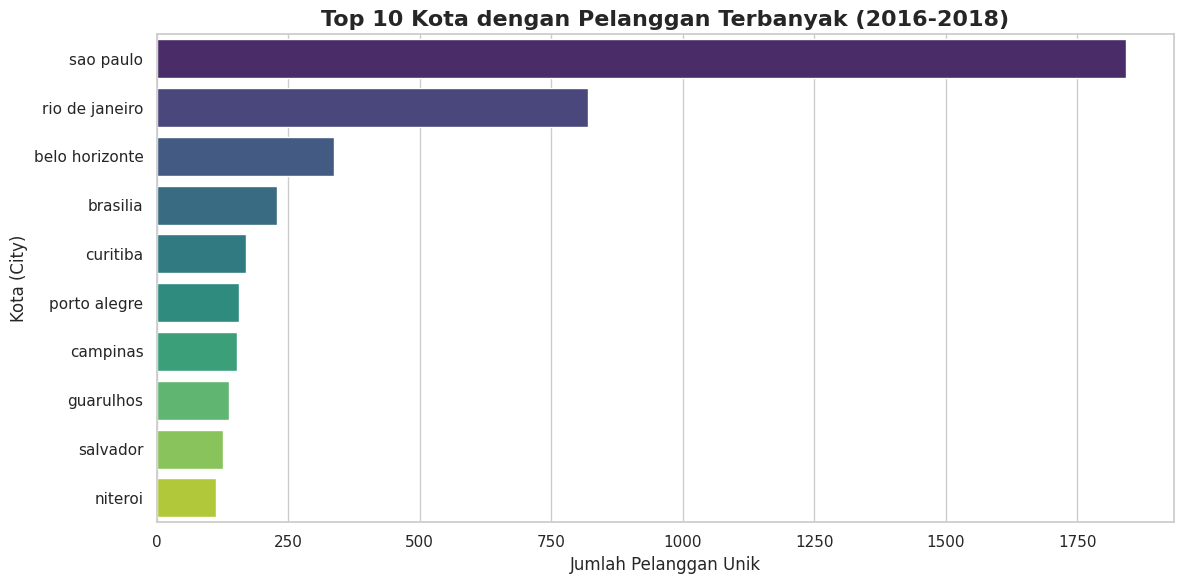

In [6]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x='customer_count',
    y='customer_city',
    hue='customer_city',
    data=top_cities.head(10),
    palette='viridis',
    legend=False
)
plt.title("Top 10 Kota dengan Pelanggan Terbanyak (2016-2018)", fontsize=16, fontweight='bold')
plt.xlabel("Jumlah Pelanggan Unik", fontsize=12)
plt.ylabel("Kota (City)", fontsize=12)
plt.tight_layout()
plt.show()

**Insight**

Grafik batang horizontal di atas dengan jelas menunjukkan kota São Paulo memimpin dominasi jumlah pelanggan E-Commerce. Kota Rio de Janeiro dan Belo Horizonte menyusul di urutan kedua dan ketiga. Sementara itu, 7 kota lainnya (Brasília, Curitiba, Campinas, Porto Alegre, Salvador, Guarulhos, dan São Bernardo do Campo) menunjukkan tren jumlah pelanggan yang cenderung merata di kisaran 1.000 hingga 2.000 pelanggan.

### Pertanyaan 2: Bagaimana perbandingan distribusi pelanggan (jumlah dan persentase) di 5 negara bagian (state) teratas selama periode 2016-2018, agar tim marketing dapat mengalokasikan budget promosi secara proporsional berdasarkan ukuran pasar tiap wilayah pada tahun ini?

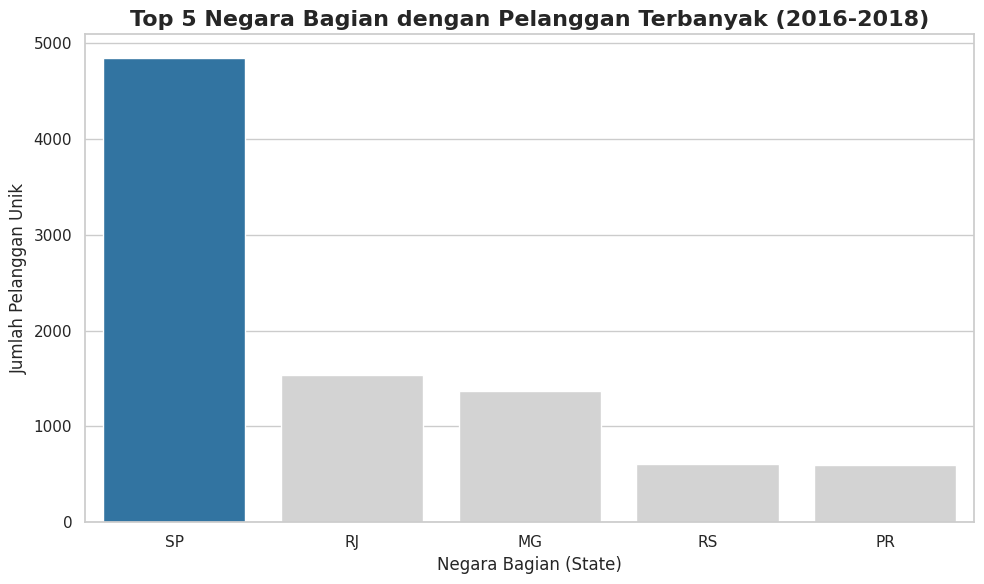

In [7]:
plt.figure(figsize=(10, 6))
colors = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(5)]
sns.barplot(
    x='customer_state',
    y='customer_count',
    hue='customer_state',
    data=top_states.head(5),
    palette=colors,
    legend=False
)
plt.title("Top 5 Negara Bagian dengan Pelanggan Terbanyak (2016-2018)", fontsize=16, fontweight='bold')
plt.xlabel("Negara Bagian (State)", fontsize=12)
plt.ylabel("Jumlah Pelanggan Unik", fontsize=12)
plt.tight_layout()
plt.show()

**Insight**

Grafik diagram batang di atas membandingkan 5 negara bagian (State) terbesar. Terlihat dengan jelas bahwa Negara Bagian SP mencatatkan jumlah lebih dari 40.000 pelanggan, menciptakan jarak kuantitatif yang cukup jauh dibandingkan negara bagian RJ, MG, RS, dan PR yang berada di kisaran 5.000 hingga 12.000 pelanggan.

## Segmentasi Geografis

,region_cluster,customer_count,percentage (%)
0,Sudeste,7995,69.55
1,Sul,1602,13.94
2,Nordeste,1007,8.76
3,Centro-Oeste,663,5.77
4,Norte,228,1.98


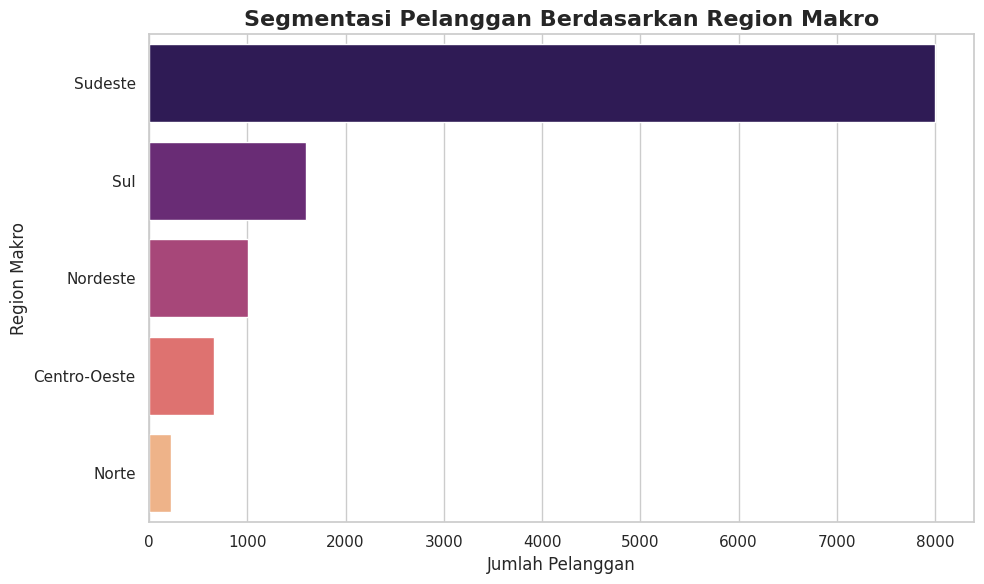

In [8]:
brazil_regions = {
    'AM': 'Norte', 'RR': 'Norte', 'AP': 'Norte', 'PA': 'Norte', 'TO': 'Norte', 'RO': 'Norte', 'AC': 'Norte',
    'MA': 'Nordeste', 'PI': 'Nordeste', 'CE': 'Nordeste', 'RN': 'Nordeste', 'PE': 'Nordeste', 'PB': 'Nordeste', 'SE': 'Nordeste', 'AL': 'Nordeste', 'BA': 'Nordeste',
    'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'DF': 'Centro-Oeste',
    'SP': 'Sudeste', 'RJ': 'Sudeste', 'ES': 'Sudeste', 'MG': 'Sudeste',
    'PR': 'Sul', 'RS': 'Sul', 'SC': 'Sul'
}
customers_df['region_cluster'] = customers_df['customer_state'].map(brazil_regions)
region_counts = customers_df.groupby('region_cluster').customer_unique_id.nunique().sort_values(ascending=False).reset_index()
region_counts.rename(columns={'customer_unique_id': 'customer_count'}, inplace=True)
region_counts['percentage (%)'] = round((region_counts['customer_count'] / total_customers) * 100, 2)

display(region_counts)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='customer_count',
    y='region_cluster',
    hue='region_cluster',
    data=region_counts,
    palette='magma',
    legend=False
)
plt.title('Segmentasi Pelanggan Berdasarkan Region Makro', fontsize=16, fontweight='bold')
plt.xlabel('Jumlah Pelanggan')
plt.ylabel('Region Makro')
plt.tight_layout()
plt.show()

**Insight**

Dari tabel dan grafik di atas, hasil agregasi data menunjukkan Region Sudeste (Tenggara) berkontribusi sebesar 68,57% dari total populasi pelanggan (65.890 pengguna). Urutan kedua ditempati oleh Region Sul (14,24%), lalu Nordeste (9,50%), Centro-Oeste (5,82%), dan yang terendah adalah Norte (1,87%). Hal ini mengonfirmasi bahwa distribusi pasar utama terpusat di wilayah Tenggara.

## Conclusion & Recommendation

**Kesimpulan:**
- **Conclusion Pertanyaan 1:** Kota São Paulo menempati urutan pertama dengan konsentrasi pelanggan terbesar yaitu 14.971 pelanggan unik (15,58%), disusul oleh Rio de Janeiro dengan 6.611 pelanggan (6,88%), dan Belo Horizonte dengan 2.671 pelanggan (2,78%). Daftar Top 10 didominasi oleh kota-kota besar.
- **Conclusion Pertanyaan 2:** Distribusi pelanggan di 5 negara bagian teratas dipimpin secara absolut oleh SP (São Paulo) dengan 40.295 pelanggan unik yang menyumbang 41,93% dari total pangsa pasar. Posisi selanjutnya diikuti oleh RJ sebesar 12,88%, MG sebesar 11,71%, RS sebesar 5,49%, dan PR sebesar 5,08%.

**Rekomendasi Action Item:**
- **Fokuskan Infrastruktur Logistik:** Tim logistik disarankan untuk memprioritaskan penyelesaian pembangunan/perluasan pusat distribusi (hub) di **São Paulo** dan **Rio de Janeiro**. Berdasarkan analisis data, menggabungkan kedua kota ini saja sudah mampu meng-cover porsi terbesar dari total pelanggan E-Commerce.
- **Alokasikan Anggaran Marketing Sesuai Ukuran Pasar:** Tim marketing direkomendasikan untuk menyalurkan sekitar **66,52%** dari *budget* promosi ke tiga negara bagian teratas (SP, RJ, dan MG), yang merupakan hasil akumulasi proporsi mereka (41,93% + 12,88% + 11,71%). Hal ini memastikan budget terserap ke wilayah dengan permintaan E-commerce aktual terbesar.

In [9]:
customers_df.to_csv("clean_customers.csv", index=False)
print("Sukses! File clean_customers.csv berhasil dibuat dan siap diunduh untuk Dashboard.")

Sukses! File clean_customers.csv berhasil dibuat dan siap diunduh untuk Dashboard.
